# Pipeline Completo — Análise de Dados e CiberInteligência

## Dataset: PQC-OAV 2025 (Post-Quantum Cryptography — Observatório de Anomalias em VPN)

**Índice do notebook:**
1. Carregamento e Visão Geral dos Dados
2. Análise Exploratória (EDA) — Estatísticas, Distribuições, Correlações
3. Tratamento de Valores em Falta
4. Aproximação à Distribuição Normal (Transformações)
5. Feature Engineering (Derivação de Novas Features)
6. Clustering (K-Means)
7. Balanceamento do Dataset (SMOTE)
8. Seleção de Features
9. Treino de Todos os Modelos (KNN, Linear Reg., Logistic Reg., Decision Tree, Random Forest, SVM)
10. Tabela Comparativa de Métricas
11. Simulação do Uso dos Modelos para um Novo Caso

In [1]:
# ============================================================
# CÉLULA 1 — IMPORTS E CONFIGURAÇÃO
# ============================================================
# Importamos todas as bibliotecas necessárias de uma vez.
# Isto evita problemas de dependências ao longo do notebook.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')  # Silenciar avisos menores para manter o output limpo

# Sklearn — Pré-processamento
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score

# Sklearn — Seleção de Features
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# Sklearn — Modelos
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Sklearn — Métricas
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# Clustering
from sklearn.cluster import KMeans

# Balanceamento
from imblearn.over_sampling import SMOTE

# Estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Todas as bibliotecas carregadas com sucesso.")

Todas as bibliotecas carregadas com sucesso.


## 1. Carregamento e Visão Geral dos Dados

In [2]:
# ============================================================
# CÉLULA 2 — CARREGAR O DATASET
# ============================================================
# Carregamos o CSV principal e o manifesto de cenários.
# O CSV principal tem ~40.010 linhas com features de tráfego
# de rede (TLS/PQC) e uma label binária (0=Normal, 1=Anomalia).
# ============================================================

# Carregar dataset principal
df = pd.read_csv('../data/raw/ml_features_and_labels.csv')

# Carregar manifesto de cenários (metadados dos cenários de teste)
manifest = pd.read_csv('../data/raw/scenario_manifest.csv')

# Visão geral rápida
print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"\nColunas disponíveis:")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")

print(f"\nPrimeiras 5 linhas:")
df.head()

Dimensões do dataset: 40010 linhas x 36 colunas

Colunas disponíveis:
   1. e2c_total_bytes
   2. e4_entropy_h
   3. e5_entropy_c
   4. e6_time_char
   5. e6b_flow_duration_ms
   6. e2_client_size
   7. e2_client_record_len
   8. e2_server_record_len
   9. e3_cert_parsed
  10. e1_alg_suite_Unknown(0x11eb)
  11. e1_alg_suite_Unknown(0x11ec)
  12. e1_alg_suite_mlkem1024
  13. e1_alg_suite_mlkem768
  14. e1_alg_suite_x25519
  15. e1_alg_suite_nan
  16. e8_proto_context_TLSv1.2_or_older
  17. e8_proto_context_TLSv1.3
  18. e9_conn_outcome_Failure
  19. e9_conn_outcome_Incomplete
  20. e9_conn_outcome_Success
  21. e3_sig_alg_Unknown(0x0028)
  22. e3_sig_alg_nan
  23. e1b_tls_version_SSL3.0
  24. e1b_tls_version_TLS1.0
  25. e1b_ciphersuite_2
  26. e1b_ciphersuite_54
  27. e1b_ciphersuite_60
  28. e2b_tls_version_SSL3.0
  29. e2b_tls_version_TLS1.0
  30. e2b_ciphersuite_2
  31. e2b_ciphersuite_54
  32. e2b_ciphersuite_60
  33. label
  34. split
  35. taxonomy
  36. ID

Primeiras 5 linhas:


,e2c_total_bytes,e4_entropy_h,e5_entropy_c,e6_time_char,e6b_flow_duration_ms,e2_client_size,e2_client_record_len,e2_server_record_len,e3_cert_parsed,e1_alg_suite_Unknown(0x11eb),...,e1b_ciphersuite_60,e2b_tls_version_SSL3.0,e2b_tls_version_TLS1.0,e2b_ciphersuite_2,e2b_ciphersuite_54,e2b_ciphersuite_60,label,split,taxonomy,ID
0,8182,4.7889,5.8077,2.45,149.827957,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,train,eval_test_network,net_high_jitter_classic_run1
1,8126,5.0000,5.8367,2.44,231.020927,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,val,eval_test_network,net_high_jitter_classic_run10
2,8272,4.7889,5.9056,2.73,292.967796,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,train,eval_test_network,net_high_jitter_classic_run100
3,8272,4.8125,5.9056,2.31,156.050205,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,test,eval_test_network,net_high_jitter_classic_run101
4,8272,4.8125,5.8367,4.45,193.972111,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,test,eval_test_network,net_high_jitter_classic_run102


## 2. Análise Exploratória de Dados (EDA)

Nesta secção vamos fazer uma análise "de elevado nível" como pede o enunciado:
- Estatísticas descritivas completas
- Distribuição das classes (label)
- Histogramas das variáveis contínuas
- Matriz de correlação
- Boxplots por classe

In [3]:
# ============================================================
# CÉLULA 3 — TIPOS DE DADOS E VALORES EM FALTA
# ============================================================
# Verificamos os tipos de cada coluna e quantos valores nulos
# existem. Isto é fundamental antes de qualquer análise.
# ============================================================

print("=== TIPOS DE DADOS ===")
print(df.dtypes)

print("\n=== VALORES EM FALTA (por coluna) ===")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Nulos': missing, 'Percentagem (%)': missing_pct})
# Mostramos apenas as colunas que têm pelo menos 1 nulo
print(missing_df[missing_df['Nulos'] > 0])
print(f"\nTotal de células vazias: {df.isnull().sum().sum()}")

=== TIPOS DE DADOS ===
e2c_total_bytes                        int64
e4_entropy_h                         float64
e5_entropy_c                         float64
e6_time_char                         float64
e6b_flow_duration_ms                 float64
e2_client_size                       float64
e2_client_record_len                   int64
e2_server_record_len                 float64
e3_cert_parsed                          bool
e1_alg_suite_Unknown(0x11eb)            bool
e1_alg_suite_Unknown(0x11ec)            bool
e1_alg_suite_mlkem1024                  bool
e1_alg_suite_mlkem768                   bool
e1_alg_suite_x25519                     bool
e1_alg_suite_nan                        bool
e8_proto_context_TLSv1.2_or_older       bool
e8_proto_context_TLSv1.3                bool
e9_conn_outcome_Failure                 bool
e9_conn_outcome_Incomplete              bool
e9_conn_outcome_Success                 bool
e3_sig_alg_Unknown(0x0028)              bool
e3_sig_alg_nan                  

In [4]:
# ============================================================
# CÉLULA 4 — ESTATÍSTICAS DESCRITIVAS COMPLETAS
# ============================================================
# O df.describe() dá-nos: contagem, média, desvio padrão,
# mínimo, quartis (25%, 50%, 75%) e máximo para cada coluna
# numérica. Isto é essencial numa EDA de "elevado nível".
# ============================================================

# Identificamos as colunas contínuas (não binárias/booleanas)
# para focar a análise nas variáveis mais interessantes
colunas_continuas = ['e2c_total_bytes', 'e4_entropy_h', 'e5_entropy_c',
                     'e6_time_char', 'e6b_flow_duration_ms',
                     'e2_client_size', 'e2_client_record_len', 'e2_server_record_len']

print("=== ESTATÍSTICAS DESCRITIVAS (variáveis contínuas) ===")
df[colunas_continuas].describe().round(4)

=== ESTATÍSTICAS DESCRITIVAS (variáveis contínuas) ===


,e2c_total_bytes,e4_entropy_h,e5_entropy_c,e6_time_char,e6b_flow_duration_ms,e2_client_size,e2_client_record_len,e2_server_record_len
count,40010.0000,40010.0000,37500.0000,39010.0000,40010.0000,39510.0000,40010.0000,39010.0000
mean,12734.8649,4.8801,5.2891,1.8825,46.0392,863.3926,1100.2697,5510.4722
std,6276.8143,0.1121,0.6992,1.6247,337.8392,650.9844,652.3256,1383.0648
min,285.0000,0.0000,4.0018,0.0700,0.0000,32.0000,129.0000,2.0000
25%,8206.0000,4.8125,4.4366,0.8300,4.6198,32.0000,285.0000,5324.0000
50%,10412.0000,4.8750,5.7787,1.2000,5.3769,1184.0000,1429.0000,5330.0000
75%,19207.0000,4.9375,5.8766,2.4600,6.6941,1568.0000,1813.0000,5333.0000
max,22615.0000,5.0000,6.1085,94.1500,4522.2239,1568.0000,1813.0000,7502.0000


=== DISTRIBUIÇÃO DAS CLASSES ===
label
0    35000
1     5010
Name: count, dtype: int64

Percentagem:
label
0    87.48
1    12.52
Name: proportion, dtype: float64


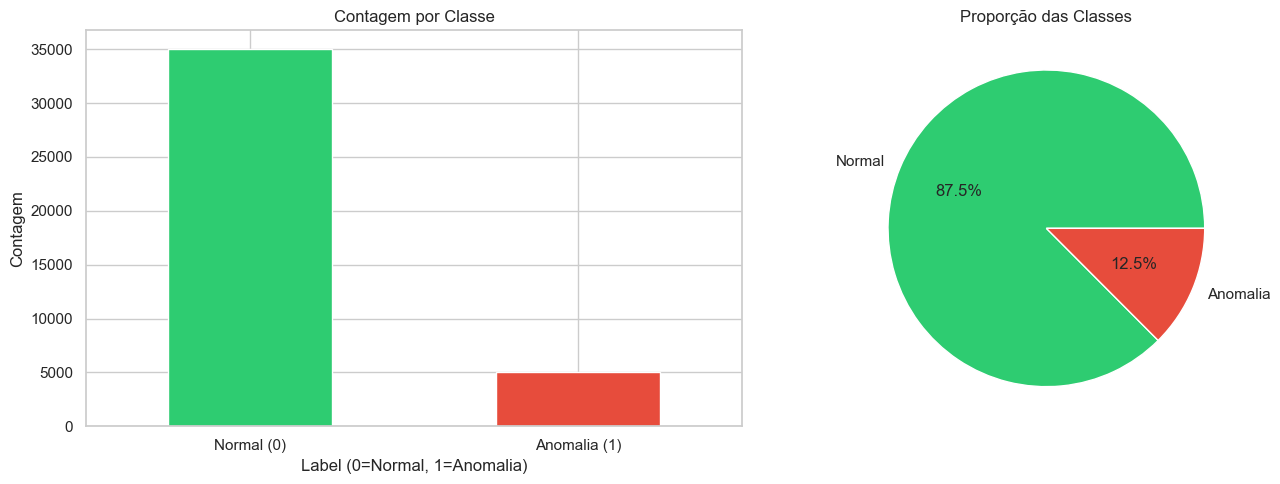

In [5]:
# ============================================================
# CÉLULA 5 — DISTRIBUIÇÃO DAS CLASSES (LABEL)
# ============================================================
# Verificar se o dataset está balanceado ou não.
# Se uma classe tiver muito mais amostras que outra,
# precisamos de balancear (SMOTE) mais à frente.
# ============================================================

print("=== DISTRIBUIÇÃO DAS CLASSES ===")
print(df['label'].value_counts())
print(f"\nPercentagem:")
print((df['label'].value_counts(normalize=True) * 100).round(2))

# Gráfico de barras da distribuição
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras
df['label'].value_counts().plot(kind='bar', ax=axes[0], color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Contagem por Classe')
axes[0].set_xlabel('Label (0=Normal, 1=Anomalia)')
axes[0].set_ylabel('Contagem')
axes[0].set_xticklabels(['Normal (0)', 'Anomalia (1)'], rotation=0)

# Gráfico circular (pie chart)
df['label'].value_counts().plot(kind='pie', ax=axes[1], autopct='%1.1f%%',
                                 colors=['#2ecc71', '#e74c3c'],
                                 labels=['Normal', 'Anomalia'])
axes[1].set_title('Proporção das Classes')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

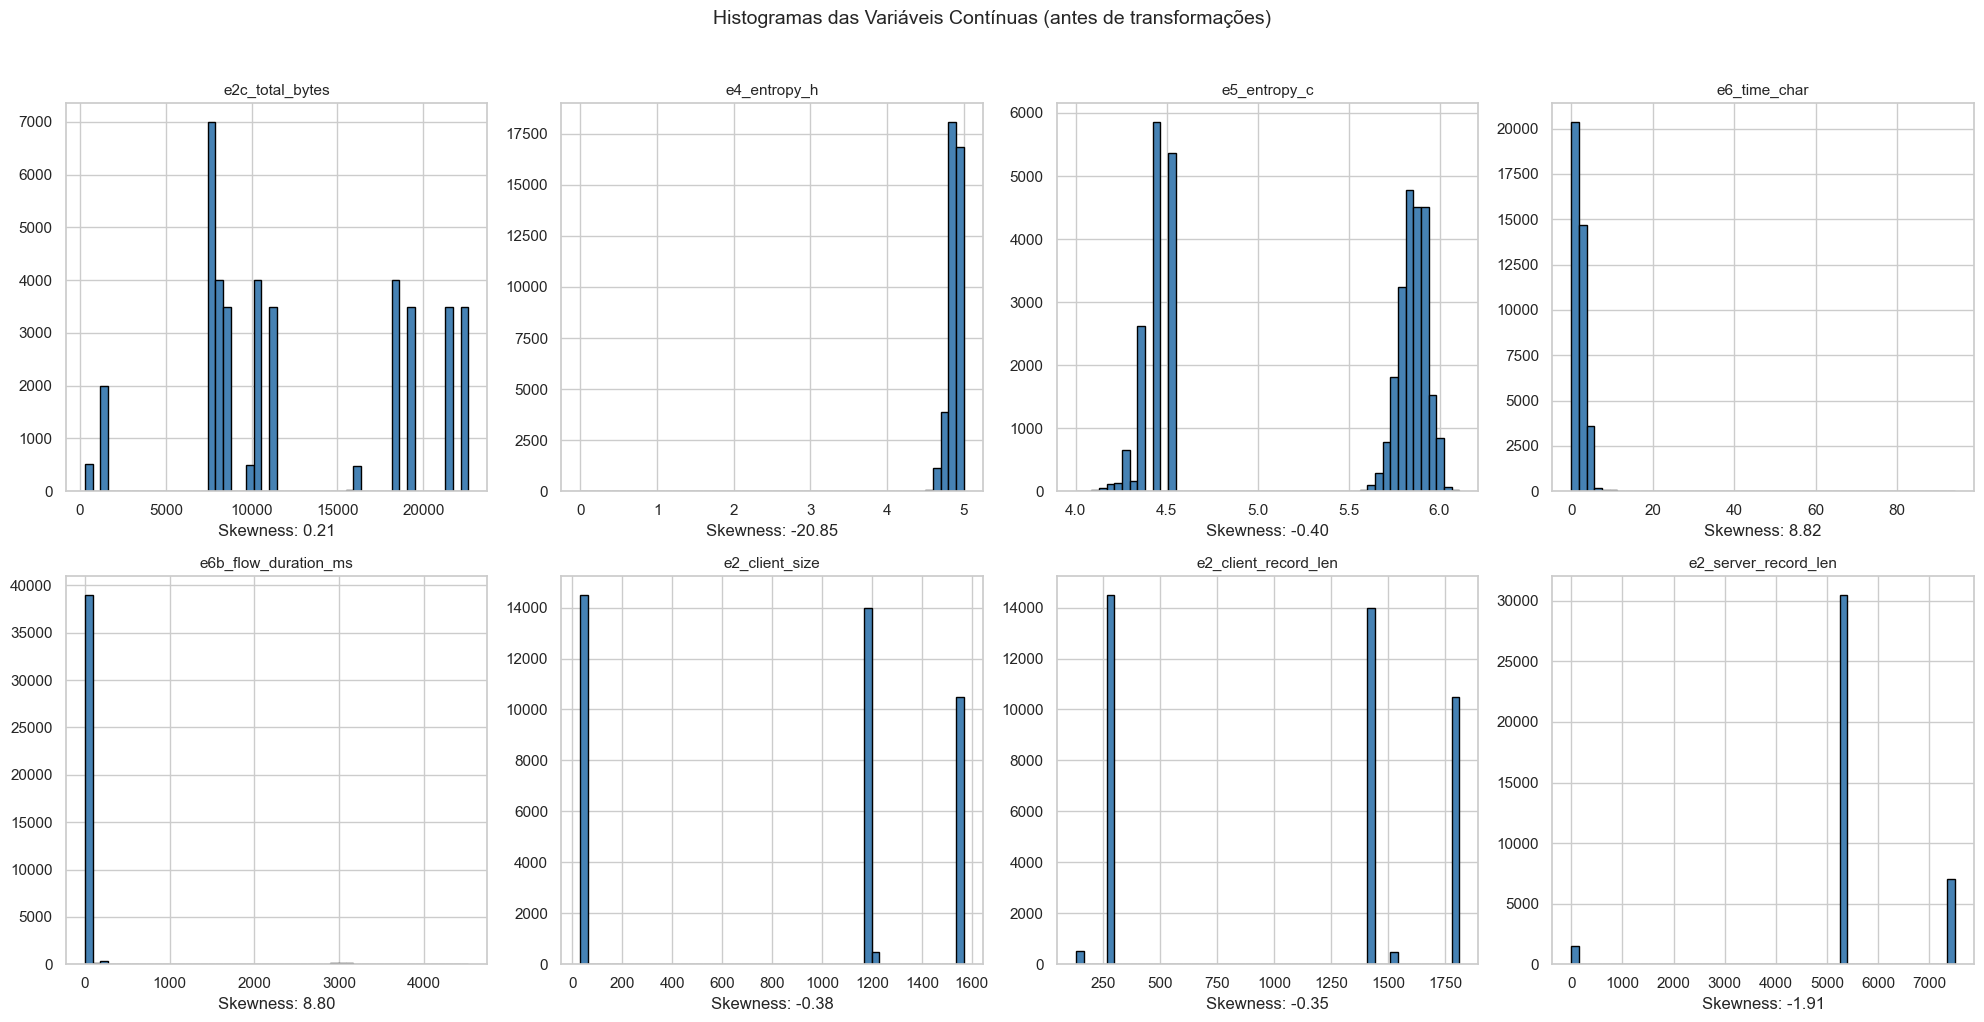

In [6]:
# ============================================================
# CÉLULA 6 — HISTOGRAMAS DAS VARIÁVEIS CONTÍNUAS
# ============================================================
# Histogramas mostram como os dados estão distribuídos.
# Se uma variável estiver muito "enviesada" (skewed), 
# precisamos de transformá-la (ponto 4 do enunciado:
# "aproximar à distribuição normal").
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(colunas_continuas):
    df[col].hist(bins=50, ax=axes[i], color='steelblue', edgecolor='black')
    axes[i].set_title(col, fontsize=11)
    # Calcular e mostrar o "skewness" (enviesamento)
    # Skewness > 1 ou < -1 indica que a variável NÃO é normal
    skew_val = df[col].skew()
    axes[i].set_xlabel(f'Skewness: {skew_val:.2f}')

plt.suptitle('Histogramas das Variáveis Contínuas (antes de transformações)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

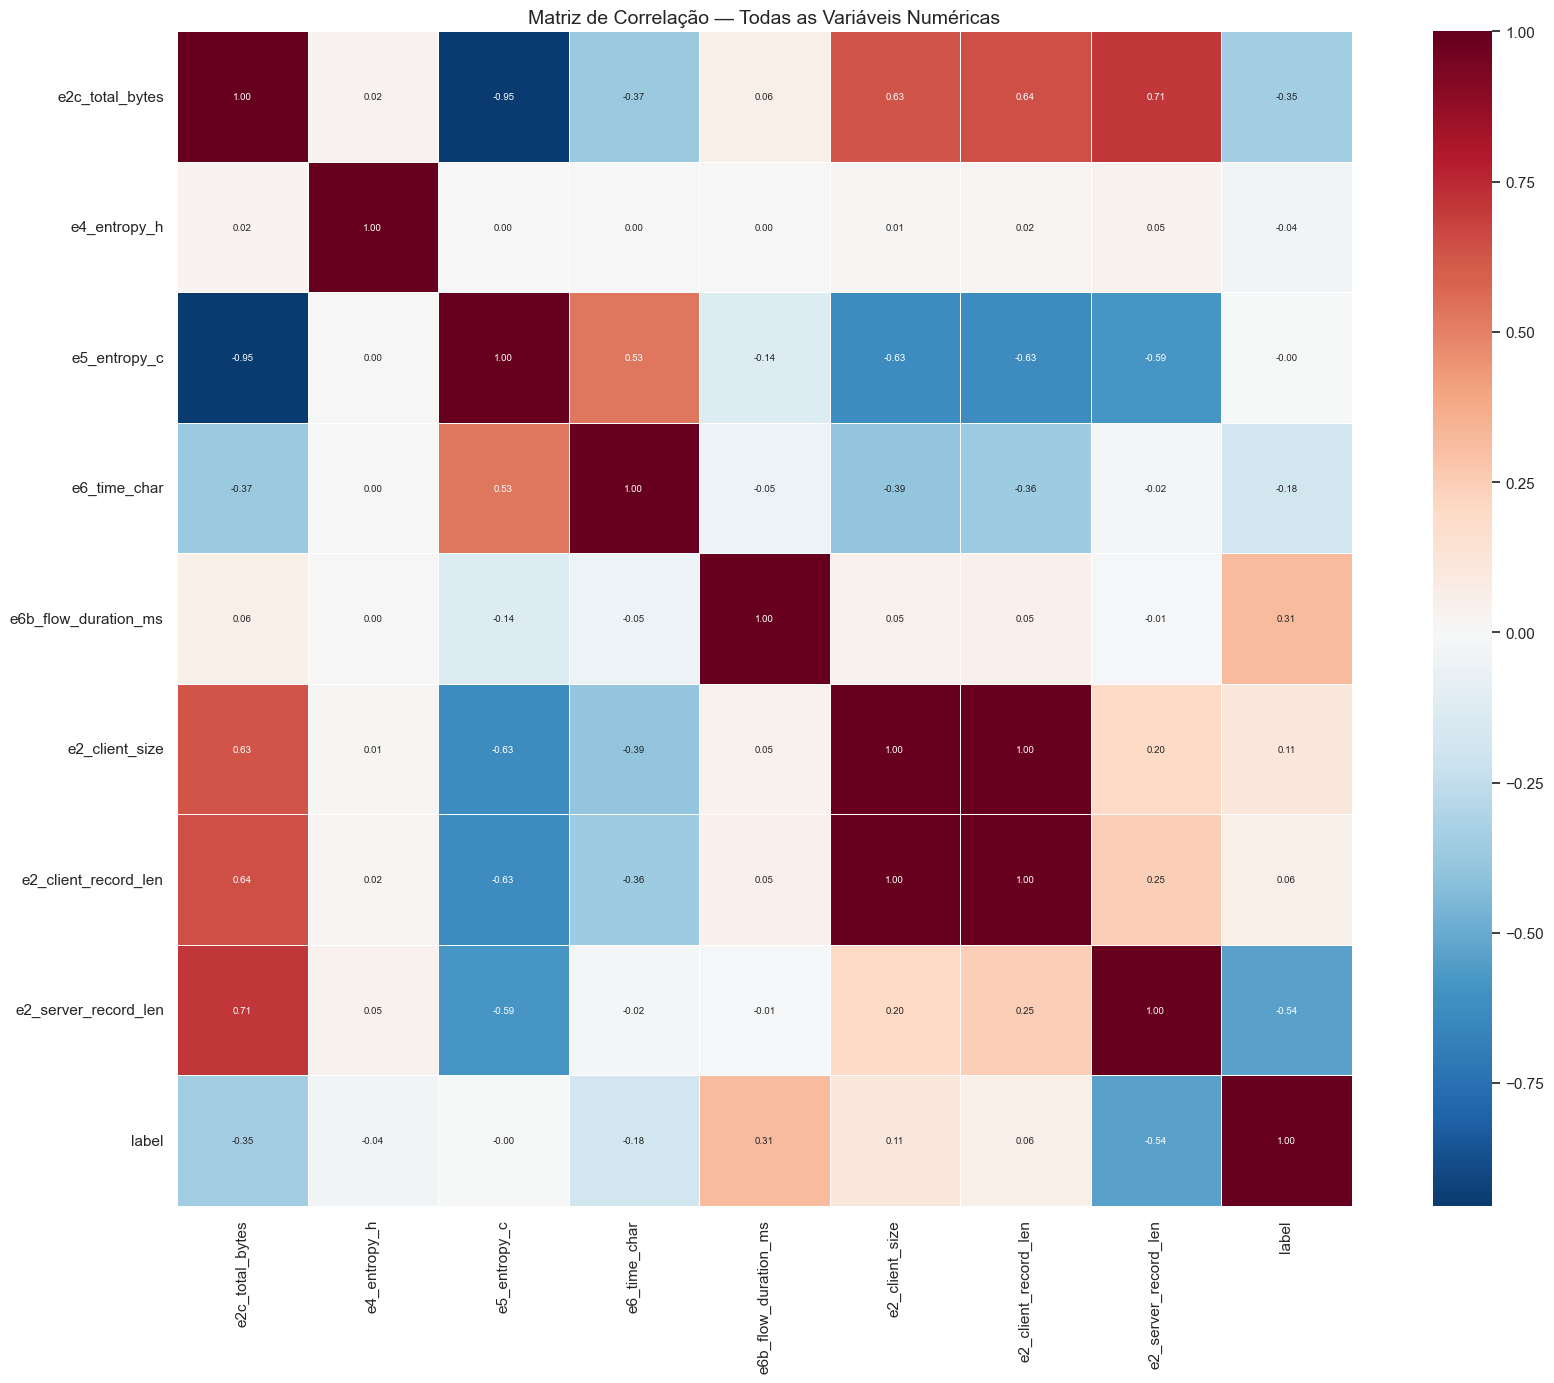


=== TOP 10 FEATURES MAIS CORRELACIONADAS COM A LABEL ===
e2_server_record_len    0.5360
e2c_total_bytes         0.3500
e6b_flow_duration_ms    0.3136
e6_time_char            0.1836
e2_client_size          0.1070
e2_client_record_len    0.0554
e4_entropy_h            0.0352
e5_entropy_c            0.0005
Name: label, dtype: float64


In [7]:
# ============================================================
# CÉLULA 7 — MATRIZ DE CORRELAÇÃO (HEATMAP)
# ============================================================
# A correlação mede a relação linear entre cada par de
# variáveis (-1 a 1). Valores perto de 1 ou -1 indicam
# forte relação. Isto ajuda-nos a:
# - Identificar features redundantes (alta correlação entre si)
# - Encontrar features que se correlacionam com a label
# ============================================================

# Selecionar apenas colunas numéricas para a correlação
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5,
            annot_kws={'size': 7})
plt.title('Matriz de Correlação — Todas as Variáveis Numéricas', fontsize=14)
plt.tight_layout()
plt.show()

# Mostrar as features mais correlacionadas com a label
print("\n=== TOP 10 FEATURES MAIS CORRELACIONADAS COM A LABEL ===")
corr_with_label = corr_matrix['label'].drop('label').abs().sort_values(ascending=False)
print(corr_with_label.head(10).round(4))

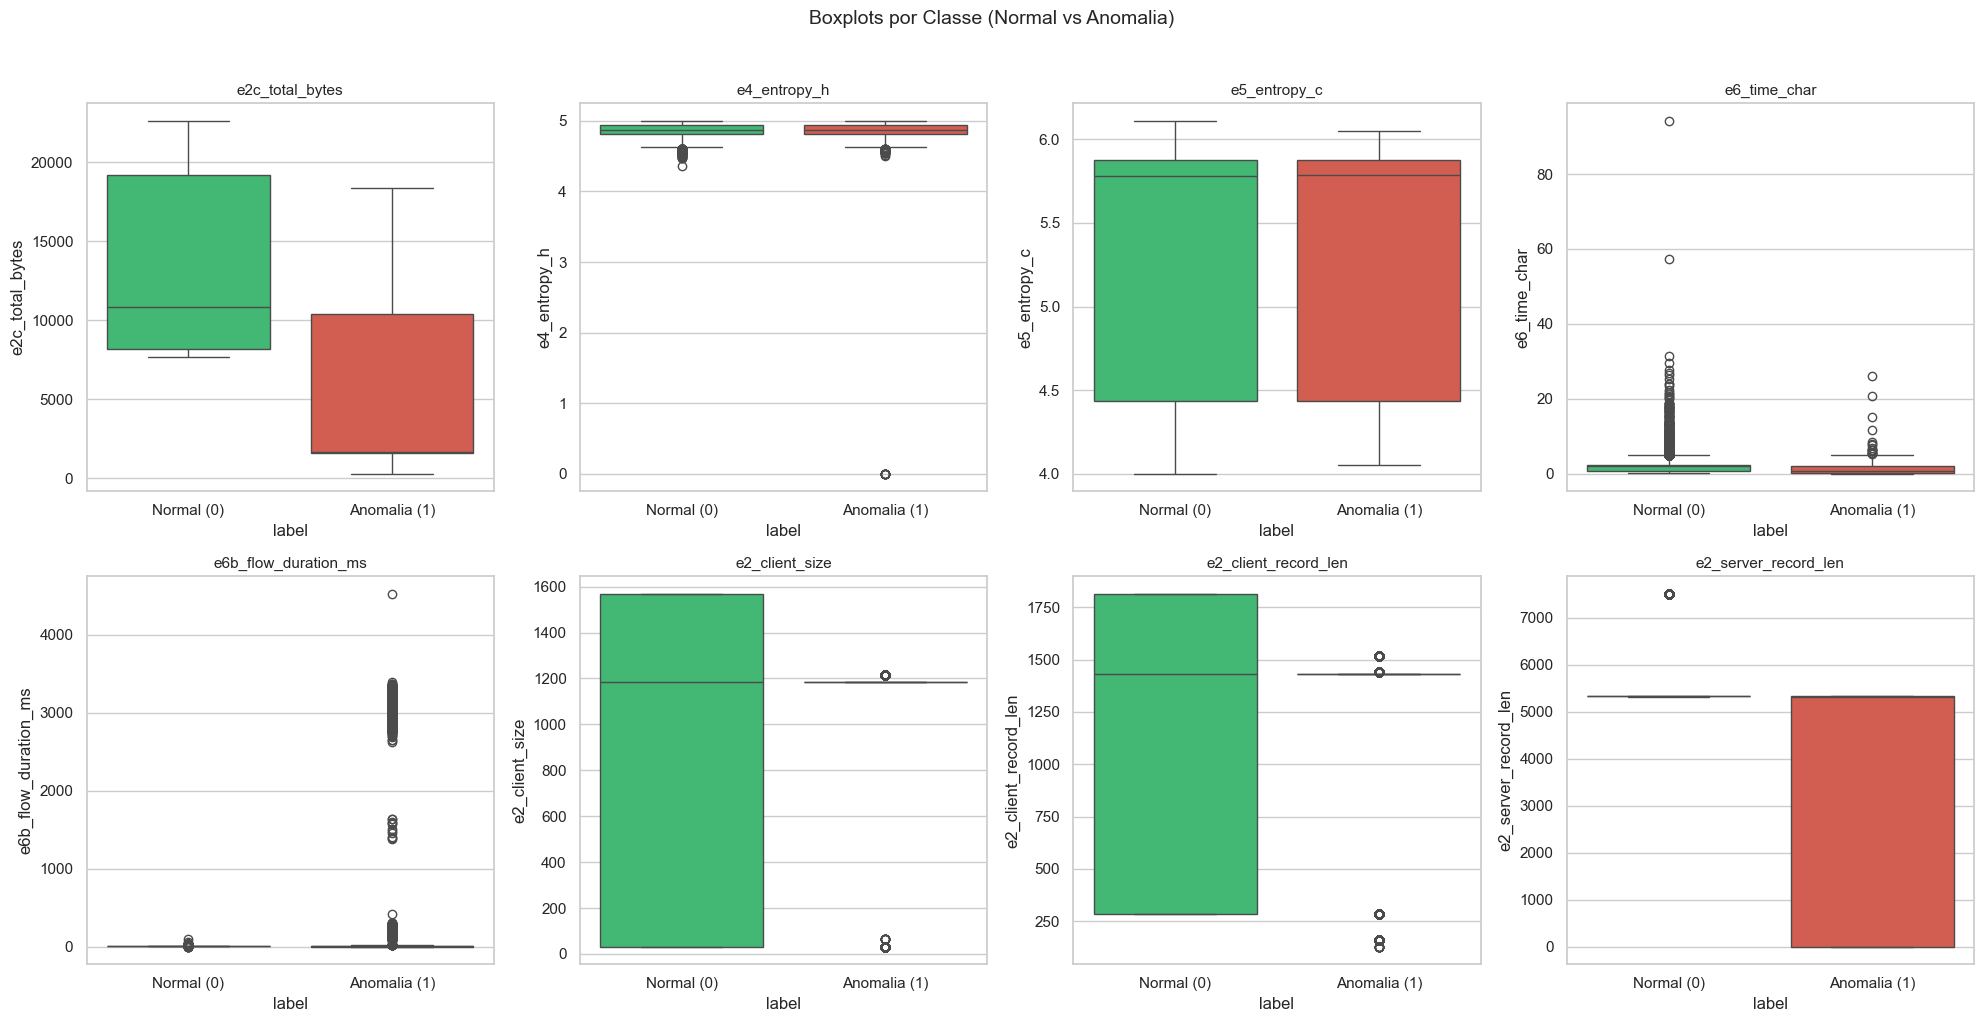

In [8]:
# ============================================================
# CÉLULA 8 — BOXPLOTS POR CLASSE (NORMAL vs ANOMALIA)
# ============================================================
# Boxplots permitem ver a distribuição por classe e detetar
# outliers. Se a distribuição for muito diferente entre
# Normal e Anomalia, essa feature é boa para classificação.
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(colunas_continuas):
    sns.boxplot(data=df, x='label', y=col, ax=axes[i],
                palette=['#2ecc71', '#e74c3c'])
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xticklabels(['Normal (0)', 'Anomalia (1)'])

plt.suptitle('Boxplots por Classe (Normal vs Anomalia)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. Tratamento de Valores em Falta

O enunciado pede para **tratar os valores em falta**. Vamos:
1. Identificar quais colunas têm nulos
2. Testar diferentes estratégias de imputação (média, mediana, constante)
3. Escolher a melhor com base no F1-Score

In [9]:
# ============================================================
# CÉLULA 9 — TESTAR ESTRATÉGIAS DE IMPUTAÇÃO
# ============================================================
# Testamos 3 formas de preencher os valores em falta:
#   - "mean": substitui pelo valor médio da coluna
#   - "median": substitui pelo valor mediano (mais robusto a outliers)
#   - "constant": substitui por 0
# Avaliamos qual é melhor com Cross-Validation (F1-Score).
# ============================================================

X_teste = df.select_dtypes(include=[np.number]).drop(columns=['label'], errors='ignore')
y_teste = df['label']

estrategias = ['mean', 'median', 'constant']
resultados_imputacao = {}

for est in estrategias:
    imputer = SimpleImputer(strategy=est)
    X_imp = imputer.fit_transform(X_teste)
    
    # Random Forest com Cross-Validation para avaliar a qualidade da imputação
    modelo = RandomForestClassifier(n_estimators=50, random_state=42)
    score = cross_val_score(modelo, X_imp, y_teste, cv=3, scoring='f1')
    resultados_imputacao[est] = score.mean()

print("=== COMPARAÇÃO DE ESTRATÉGIAS DE IMPUTAÇÃO ===")
for est, valor in resultados_imputacao.items():
    print(f"  Estratégia '{est}': F1-Score Médio = {valor:.4f}")

# Escolher a melhor
melhor = max(resultados_imputacao, key=resultados_imputacao.get)
print(f"\n>>> Melhor estratégia: '{melhor}' (F1 = {resultados_imputacao[melhor]:.4f})")

=== COMPARAÇÃO DE ESTRATÉGIAS DE IMPUTAÇÃO ===
  Estratégia 'mean': F1-Score Médio = 0.3865
  Estratégia 'median': F1-Score Médio = 0.3991
  Estratégia 'constant': F1-Score Médio = 0.4145

>>> Melhor estratégia: 'constant' (F1 = 0.4145)


In [10]:
# ============================================================
# CÉLULA 10 — APLICAR IMPUTAÇÃO ESCOLHIDA
# ============================================================
# Aplicamos a melhor estratégia de imputação ao dataset.
# Usamos a mediana por ser robusta a outliers (valores extremos).
# ============================================================

df_clean = df.copy()

# Aplicar imputação com a mediana nas colunas numéricas que têm nulos
colunas_com_nulos = df_clean.columns[df_clean.isnull().any()].tolist()
print(f"Colunas com valores em falta: {colunas_com_nulos}")

for col in colunas_com_nulos:
    if df_clean[col].dtype in ['float64', 'int64']:
        mediana = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(mediana)
        print(f"  '{col}' preenchida com mediana = {mediana}")

print(f"\nNulos restantes: {df_clean.isnull().sum().sum()}")
print("Tratamento de valores em falta concluido.")

Colunas com valores em falta: ['e5_entropy_c', 'e6_time_char', 'e2_client_size', 'e2_server_record_len']
  'e5_entropy_c' preenchida com mediana = 5.7787
  'e6_time_char' preenchida com mediana = 1.2
  'e2_client_size' preenchida com mediana = 1184.0
  'e2_server_record_len' preenchida com mediana = 5330.0

Nulos restantes: 0
Tratamento de valores em falta concluido.


## 4. Aproximação à Distribuição Normal (Transformações)

O enunciado pede explicitamente para **"aproximar as variáveis à distribuição normal"**.  
Usamos a transformação **Yeo-Johnson** (do sklearn), que funciona com valores positivos e negativos, ao contrário da Box-Cox que só aceita valores positivos.

In [11]:
# ============================================================
# CÉLULA 11 — TRANSFORMAÇÃO YEO-JOHNSON
# ============================================================
# Yeo-Johnson é uma transformação matemática que "puxa"
# as variáveis para mais perto de uma distribuição normal.
# É semelhante à Box-Cox mas funciona com valores ≤ 0.
#
# PowerTransformer do sklearn aplica Yeo-Johnson + StandardScaler
# (centra em média=0 e desvio padrão=1 automaticamente).
#
# Apenas transformamos as variáveis contínuas, NÃO as binárias
# (flags TRUE/FALSE não precisam de ser normalizadas).
# ============================================================

# Aplicar Yeo-Johnson apenas às colunas contínuas
pt = PowerTransformer(method='yeo-johnson', standardize=True)
df_clean[colunas_continuas] = pt.fit_transform(df_clean[colunas_continuas])

# Comparar o skewness antes e depois
print("=== SKEWNESS ANTES vs DEPOIS DA TRANSFORMAÇÃO ===")
print(f"{'Coluna':<25} {'Antes':>10} {'Depois':>10}")
print("-" * 47)
for col in colunas_continuas:
    skew_antes = df[col].skew()
    skew_depois = df_clean[col].skew()
    print(f"{col:<25} {skew_antes:>10.3f} {skew_depois:>10.3f}")

print("\n(Valores de skewness perto de 0 indicam distribuição mais normal)")

=== SKEWNESS ANTES vs DEPOIS DA TRANSFORMAÇÃO ===
Coluna                         Antes     Depois
-----------------------------------------------
e2c_total_bytes                0.215     -0.101
e4_entropy_h                 -20.846     -0.086
e5_entropy_c                  -0.405     -0.456
e6_time_char                   8.818      0.034
e6b_flow_duration_ms           8.803     -0.554
e2_client_size                -0.384     -0.522
e2_client_record_len          -0.355     -0.401
e2_server_record_len          -1.912     -0.776

(Valores de skewness perto de 0 indicam distribuição mais normal)


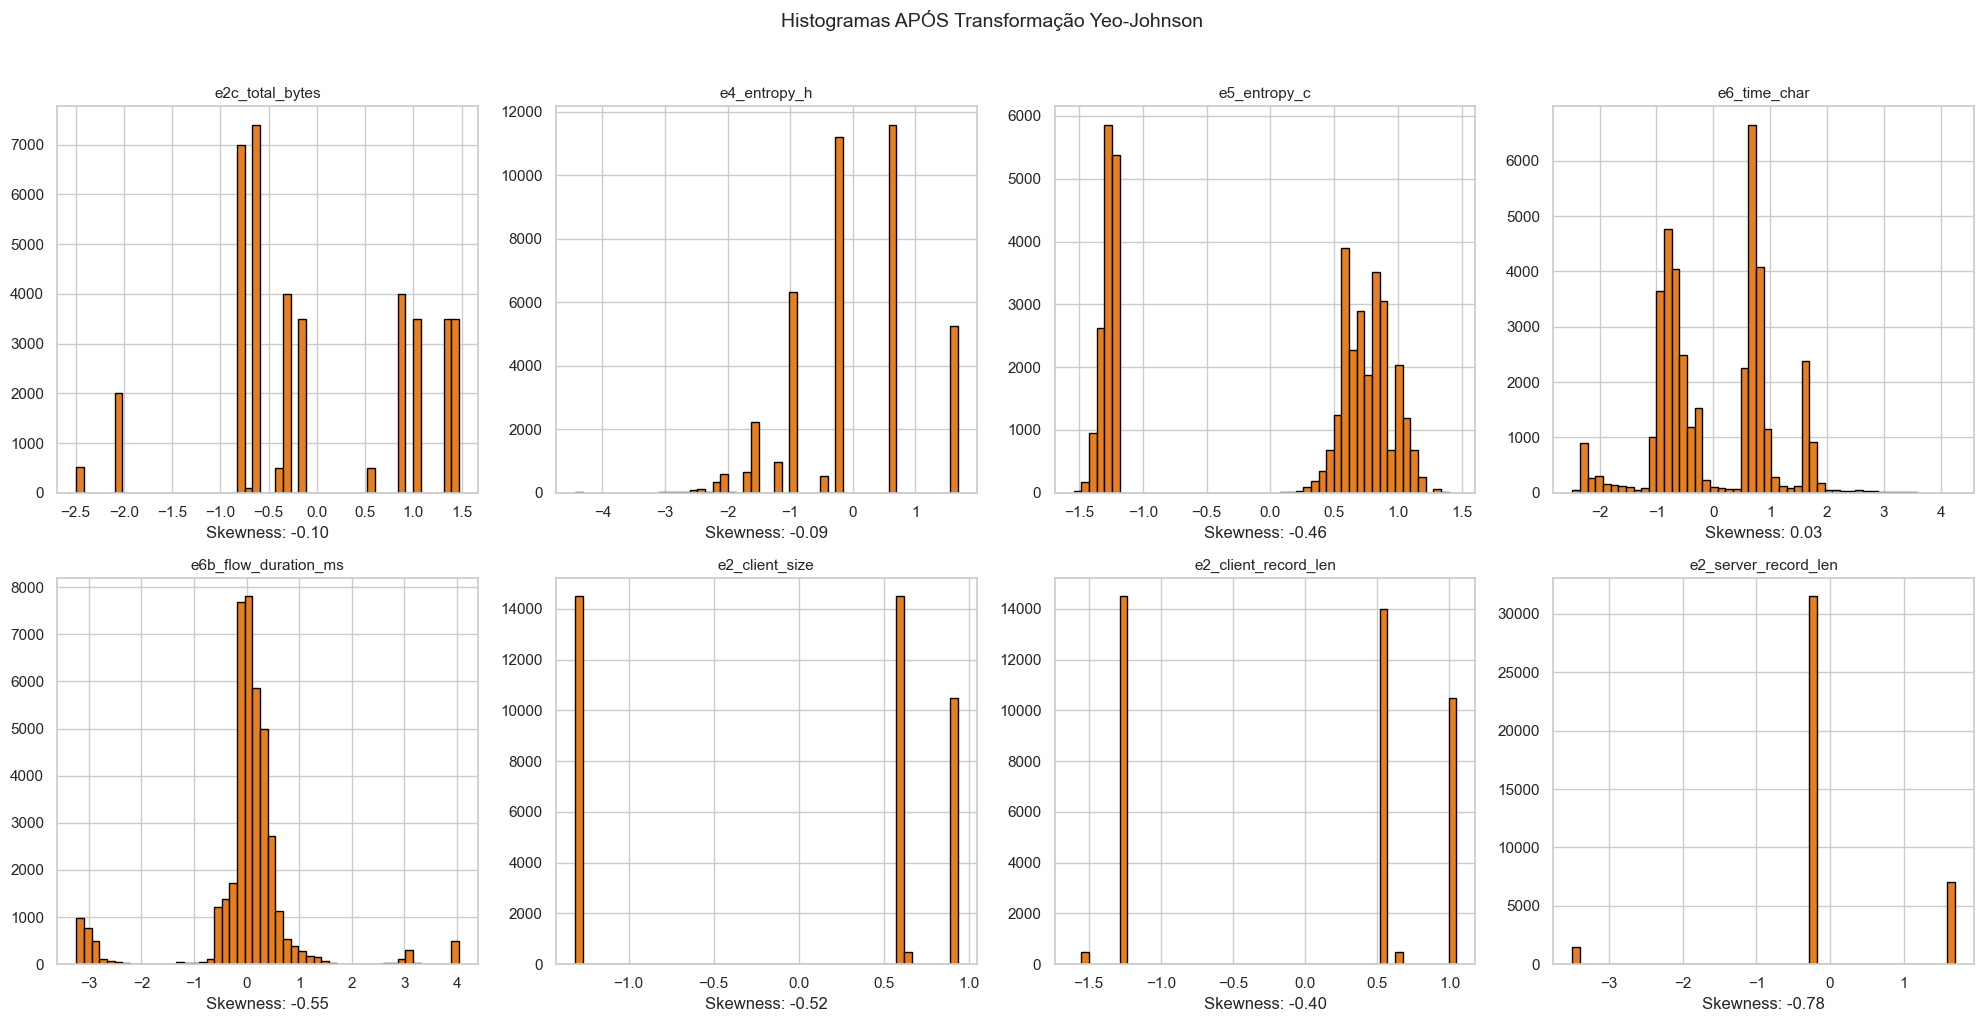

In [12]:
# ============================================================
# CÉLULA 12 — HISTOGRAMAS APÓS TRANSFORMAÇÃO
# ============================================================
# Comparamos visualmente as distribuições antes e depois
# da transformação Yeo-Johnson. Devem estar mais "simétricas".
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(colunas_continuas):
    df_clean[col].hist(bins=50, ax=axes[i], color='#e67e22', edgecolor='black')
    axes[i].set_title(col, fontsize=11)
    skew_val = df_clean[col].skew()
    axes[i].set_xlabel(f'Skewness: {skew_val:.2f}')

plt.suptitle('Histogramas APÓS Transformação Yeo-Johnson', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 5. Feature Engineering (Derivação de Novas Features)

O enunciado pede para **"derivar novas features se necessário/útil"**.  
Criamos features com significado na área de cibersegurança, combinando as existentes.

In [13]:
# ============================================================
# CÉLULA 13 — CRIAR NOVAS FEATURES
# ============================================================
# Combinamos features existentes para criar novas que possam
# conter informação relevante para a deteção de anomalias.
#
# NOTA: Como as colunas contínuas já foram transformadas
# (Yeo-Johnson), usamos os valores transformados.
# As novas features capturam padrões que os modelos
# podem não capturar só com as features originais.
# ============================================================

# 1. Rácio de entropia: se a comunicação cifrada tem padrões estranhos
#    Um valor alto pode indicar tráfego anómalo
df_clean['entropy_ratio'] = df_clean['e4_entropy_h'] / (df_clean['e5_entropy_c'] + 1e-8)

# 2. Bytes por milissegundo (throughput):
#    Tráfego legítimo tende a ter um ritmo regular
df_clean['bytes_per_ms'] = df_clean['e2c_total_bytes'] / (df_clean['e6b_flow_duration_ms'] + 1e-8)

# 3. Diferença entre tamanho do cliente e do servidor:
#    Uma grande assimetria pode indicar exfiltração de dados
df_clean['client_server_diff'] = df_clean['e2_client_size'] - df_clean['e2_server_record_len']

# 4. Rácio tamanho do registo do cliente vs total de bytes:
#    Ajuda a detetar comunicações com payloads anómalos
df_clean['record_to_total_ratio'] = df_clean['e2_client_record_len'] / (df_clean['e2c_total_bytes'] + 1e-8)

# 5. Flag: protocolo TLS antigo (potencial vulnerabilidade)
#    SSL3.0 e TLS1.0 são considerados inseguros
df_clean['is_old_tls'] = (
    df_clean['e1b_tls_version_SSL3.0'].astype(int) |
    df_clean['e1b_tls_version_TLS1.0'].astype(int) |
    df_clean['e2b_tls_version_SSL3.0'].astype(int) |
    df_clean['e2b_tls_version_TLS1.0'].astype(int)
).astype(int)

# 6. Interação entre time_char e entropia:
#    Captura padrões temporais no conteúdo cifrado
df_clean['time_entropy_interaction'] = df_clean['e6_time_char'] * df_clean['e4_entropy_h']

print("=== NOVAS FEATURES CRIADAS ===")
novas_features = ['entropy_ratio', 'bytes_per_ms', 'client_server_diff',
                  'record_to_total_ratio', 'is_old_tls', 'time_entropy_interaction']
for feat in novas_features:
    print(f"  - {feat}: min={df_clean[feat].min():.4f}, max={df_clean[feat].max():.4f}")

print(f"\nDataset agora tem {df_clean.shape[1]} colunas (antes: {df.shape[1]})")

=== NOVAS FEATURES CRIADAS ===
  - entropy_ratio: min=-47.1708, max=19.1322
  - bytes_per_ms: min=-32207.2236, max=14593.3489
  - client_server_diff: min=-1.1096, max=4.1184
  - record_to_total_ratio: min=-6.9320, max=2.1135
  - is_old_tls: min=1.0000, max=1.0000
  - time_entropy_interaction: min=-9.9836, max=11.0131

Dataset agora tem 42 colunas (antes: 36)


## 6. Clustering (K-Means)

O enunciado pede **"exploração do clustering"**. Usamos K-Means para encontrar grupos naturais nos dados.  
Primeiro usamos o método do Cotovelo (Elbow) para determinar o número ideal de clusters.

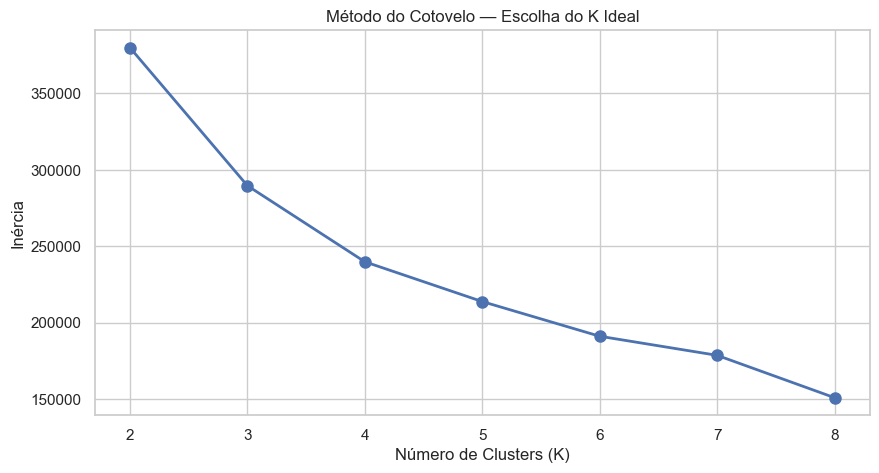

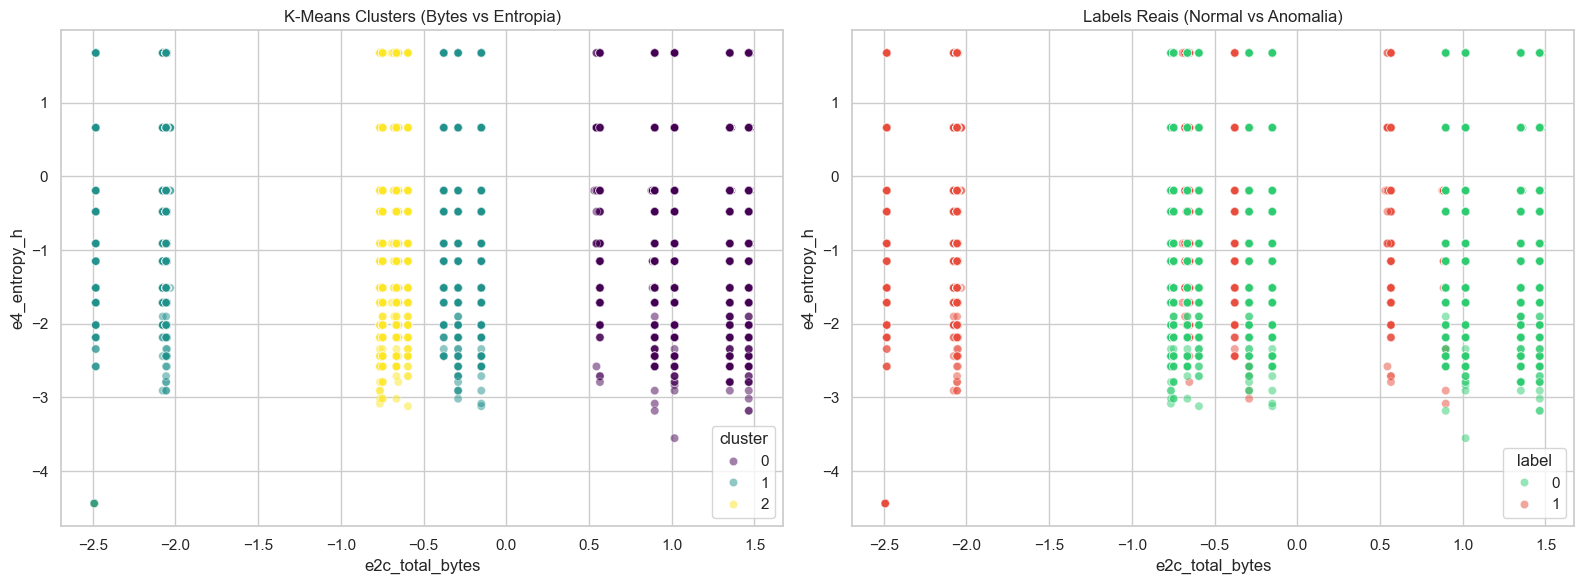


=== COMPARAÇÃO: CLUSTERS vs LABELS REAIS ===
Label        0     1
Cluster             
0        14000  1000
1         7000  3509
2        14000   501


In [14]:
# ============================================================
# CÉLULA 14 — MÉTODO DO COTOVELO + K-MEANS
# ============================================================
# O método do cotovelo (Elbow Method) testa vários valores de
# K (número de clusters) e mede a "inércia" (distância dos
# pontos ao centro do seu cluster). O K ideal é onde a curva
# faz um "cotovelo" (melhoria começa a ser marginal).
# ============================================================

# Preparar dados para clustering: só colunas numéricas, sem label
X_clustering = df_clean.select_dtypes(include=[np.number]).drop(columns=['label'], errors='ignore')
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_clustering)

# Testar K de 2 a 8
inertias = []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)

# Gráfico do Cotovelo
plt.figure(figsize=(10, 5))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia')
plt.title('Método do Cotovelo — Escolha do K Ideal')
plt.xticks(K_range)
plt.grid(True)
plt.show()

# Aplicar K-Means com K escolhido (3 é típico para Normal/Ataque/Intermédio)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['cluster'] = kmeans.fit_predict(X_cluster_scaled)

# Visualizar clusters
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Clusters
sns.scatterplot(data=df_clean, x='e2c_total_bytes', y='e4_entropy_h',
                hue='cluster', palette='viridis', alpha=0.5, ax=axes[0])
axes[0].set_title('K-Means Clusters (Bytes vs Entropia)')

# Comparar com labels reais
sns.scatterplot(data=df_clean, x='e2c_total_bytes', y='e4_entropy_h',
                hue='label', palette=['#2ecc71', '#e74c3c'], alpha=0.5, ax=axes[1])
axes[1].set_title('Labels Reais (Normal vs Anomalia)')

plt.tight_layout()
plt.show()

# Tabela cruzada: clusters vs labels
print("\n=== COMPARAÇÃO: CLUSTERS vs LABELS REAIS ===")
print(pd.crosstab(df_clean['cluster'], df_clean['label'],
                  rownames=['Cluster'], colnames=['Label']))

## 7. Balanceamento do Dataset (SMOTE)

O enunciado pede para **"balancear o dataset"**.  
Usamos **SMOTE** (Synthetic Minority Oversampling Technique) que cria exemplos sintéticos da classe minoritária.  
**Importante:** O SMOTE só é aplicado ao conjunto de **treino**, nunca ao de teste!

In [15]:
# ============================================================
# CÉLULA 15 — PREPARAÇÃO DOS DADOS + SMOTE
# ============================================================
# 1. Separar features (X) e target (y)
# 2. Dividir em treino/teste (80/20)
# 3. Aplicar SMOTE APENAS ao treino
#
# REGRA DE OURO: O conjunto de teste NUNCA é tocado pelo
# SMOTE, porque queremos avaliar com dados "reais".
# ============================================================

# Remover colunas não-numéricas e auxiliares
colunas_a_remover = ['label', 'split', 'taxonomy', 'ID', 'cluster']
X_all = df_clean.select_dtypes(include=[np.number]).drop(
    columns=[c for c in colunas_a_remover if c in df_clean.columns], errors='ignore'
)
y_all = df_clean['label']

# Guardar os nomes das features para usar depois
feature_names = X_all.columns.tolist()
print(f"Features selecionadas: {len(feature_names)}")

# Dividir em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
    # stratify=y_all garante que a proporção das classes é mantida em ambos os conjuntos
)

print(f"\nAntes do SMOTE:")
print(f"  Treino: {y_train.value_counts().to_dict()}")
print(f"  Teste:  {y_test.value_counts().to_dict()}")

# Aplicar SMOTE ao conjunto de treino
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(f"\nDepois do SMOTE (só treino):")
print(f"  Treino: {pd.Series(y_train_bal).value_counts().to_dict()}")
print(f"  Teste:  {y_test.value_counts().to_dict()} (inalterado)")

Features selecionadas: 14

Antes do SMOTE:
  Treino: {0: 28000, 1: 4008}
  Teste:  {0: 7000, 1: 1002}

Depois do SMOTE (só treino):
  Treino: {1: 28000, 0: 28000}
  Teste:  {0: 7000, 1: 1002} (inalterado)


## 8. Seleção de Features

O enunciado pede **"fazer a seleção de features usando um ou mais modos"**.  
Aplicamos **3 métodos** diferentes:
1. **SelectKBest com ANOVA (f_classif)** — testa se a média de cada feature difere entre classes
2. **Mutual Information** — mede a dependência entre feature e target (captura relações não-lineares)
3. **Importância do Random Forest** — mede quanto cada feature contribui para a decisão

=== TOP 15 FEATURES POR CADA MÉTODO ===

             ANOVA (F-score)               Mutual Info             Random Forest
0         client_server_diff     record_to_total_ratio      e6b_flow_duration_ms
1            e2c_total_bytes           e2c_total_bytes           e2c_total_bytes
2       e2_server_record_len              e6_time_char        client_server_diff
3               e6_time_char        client_server_diff              e6_time_char
4             e2_client_size      e6b_flow_duration_ms     record_to_total_ratio
5       e6b_flow_duration_ms  time_entropy_interaction              bytes_per_ms
6               e5_entropy_c              e5_entropy_c      e2_server_record_len
7       e2_client_record_len             entropy_ratio      e2_client_record_len
8      record_to_total_ratio              bytes_per_ms            e2_client_size
9              entropy_ratio      e2_client_record_len              e5_entropy_c
10              e4_entropy_h      e2_server_record_len  time_entropy

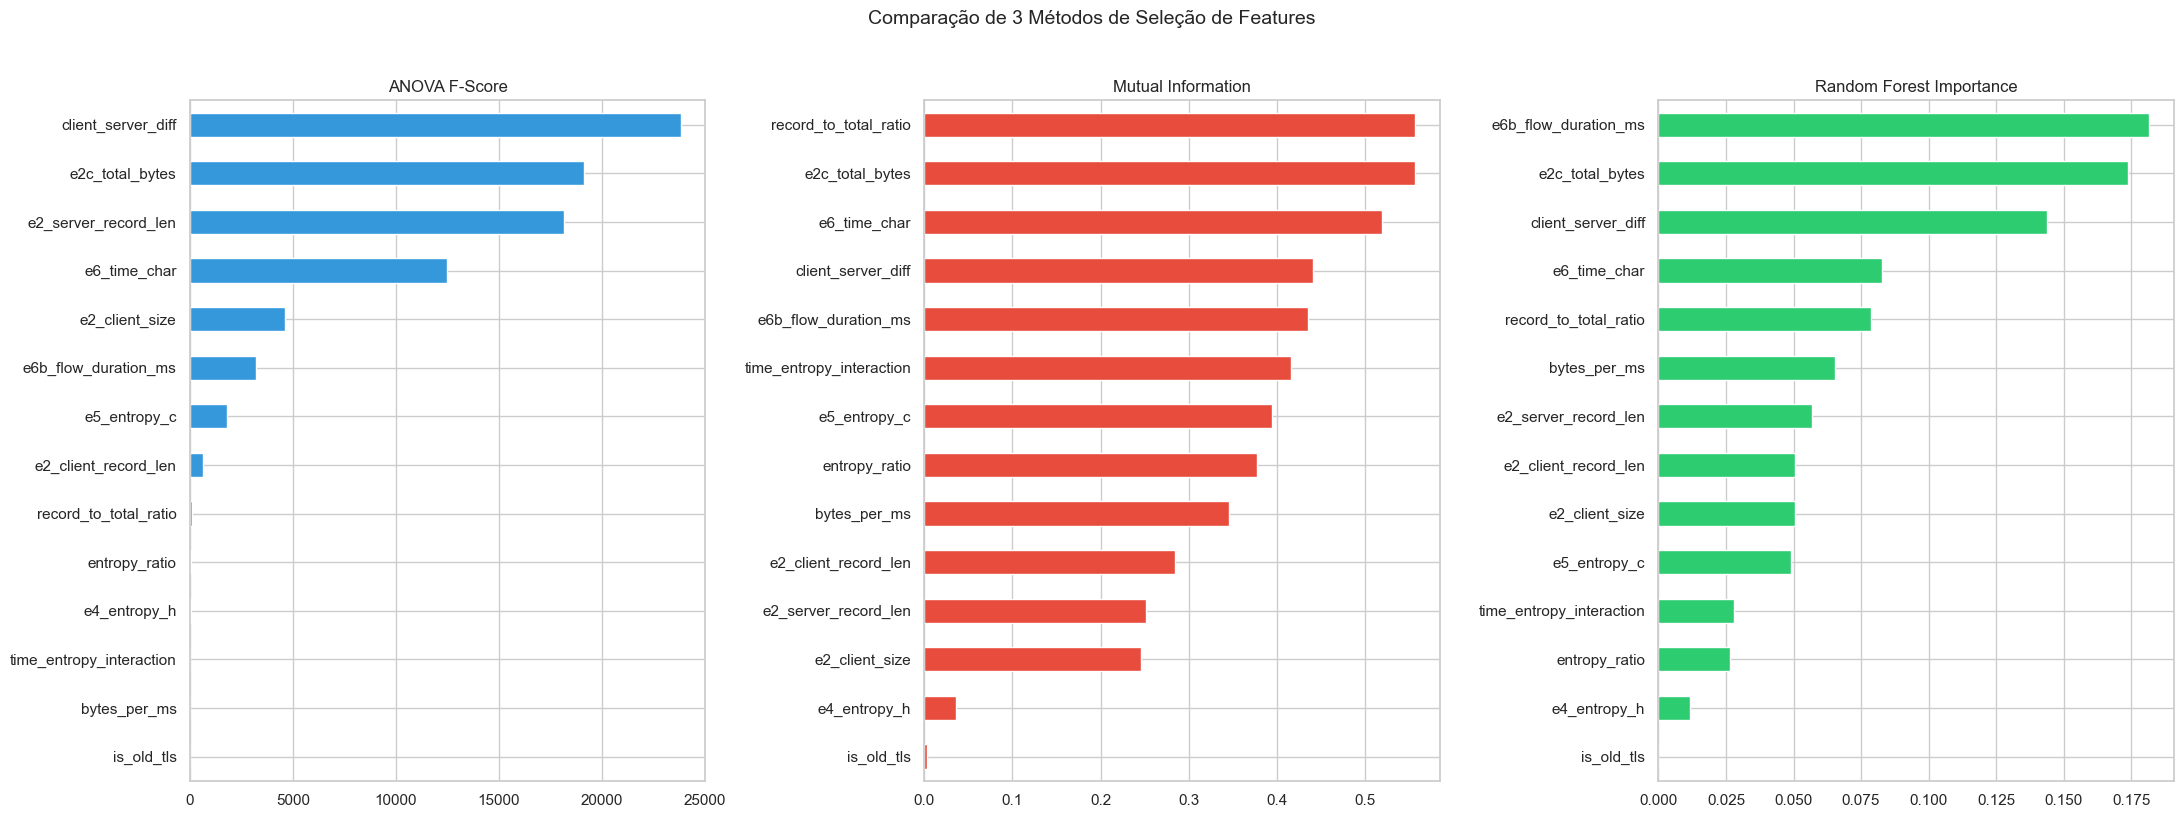

In [16]:
# ============================================================
# CÉLULA 16 — SELEÇÃO DE FEATURES (3 MÉTODOS)
# ============================================================
# Cada método classifica as features por importância.
# Depois combinamos os rankings para escolher as melhores.
# ============================================================

# --- MÉTODO 1: SelectKBest com ANOVA F-test ---
# ANOVA testa se a média da feature é significativamente
# diferente entre classes (Normal vs Anomalia)
selector_anova = SelectKBest(score_func=f_classif, k='all')
selector_anova.fit(X_train_bal, y_train_bal)
scores_anova = pd.Series(selector_anova.scores_, index=feature_names).sort_values(ascending=False)

# --- MÉTODO 2: Mutual Information ---
# Mede a dependência estatística entre cada feature e o target
# Captura relações não-lineares (ao contrário da correlação)
mi_scores = mutual_info_classif(X_train_bal, y_train_bal, random_state=42)
scores_mi = pd.Series(mi_scores, index=feature_names).sort_values(ascending=False)

# --- MÉTODO 3: Feature Importance do Random Forest ---
# O RF mede quanto cada feature contribui para reduzir a impureza
rf_temp = RandomForestClassifier(n_estimators=100, random_state=42)
rf_temp.fit(X_train_bal, y_train_bal)
scores_rf = pd.Series(rf_temp.feature_importances_, index=feature_names).sort_values(ascending=False)

# Mostrar os rankings lado a lado
print("=== TOP 15 FEATURES POR CADA MÉTODO ===\n")
rankings = pd.DataFrame({
    'ANOVA (F-score)': scores_anova.head(15).index,
    'Mutual Info': scores_mi.head(15).index,
    'Random Forest': scores_rf.head(15).index,
})
print(rankings.to_string(index=True))

# Gráfico comparativo
fig, axes = plt.subplots(1, 3, figsize=(22, 8))

scores_anova.head(15).plot(kind='barh', ax=axes[0], color='#3498db')
axes[0].set_title('ANOVA F-Score')
axes[0].invert_yaxis()

scores_mi.head(15).plot(kind='barh', ax=axes[1], color='#e74c3c')
axes[1].set_title('Mutual Information')
axes[1].invert_yaxis()

scores_rf.head(15).plot(kind='barh', ax=axes[2], color='#2ecc71')
axes[2].set_title('Random Forest Importance')
axes[2].invert_yaxis()

plt.suptitle('Comparação de 3 Métodos de Seleção de Features', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [17]:
# ============================================================
# CÉLULA 17 — SELECIONAR AS MELHORES FEATURES
# ============================================================
# Combinamos os 3 rankings: uma feature é selecionada se
# aparecer no top 15 de pelo menos 2 dos 3 métodos.
# Isto garante que escolhemos features robustas.
# ============================================================

from collections import Counter

# Juntar os top 15 de cada método
top_anova = set(scores_anova.head(15).index)
top_mi = set(scores_mi.head(15).index)
top_rf = set(scores_rf.head(15).index)

# Contar em quantos métodos cada feature aparece
todas_top = list(top_anova) + list(top_mi) + list(top_rf)
contagem = Counter(todas_top)

# Selecionar features que aparecem em 2+ métodos
features_selecionadas = [f for f, count in contagem.items() if count >= 2]
features_selecionadas.sort()

print(f"=== FEATURES SELECIONADAS ({len(features_selecionadas)}) ===")
print("(Aparecem no top 15 de pelo menos 2 dos 3 métodos)\n")
for f in features_selecionadas:
    n_metodos = contagem[f]
    print(f"  - {f} (em {n_metodos}/3 métodos)")

# Se poucas features forem selecionadas, usar todas
if len(features_selecionadas) < 5:
    print("\nATENÇÃO: Poucas features concordantes. Vamos usar todas as features.")
    features_selecionadas = feature_names

# Filtrar os conjuntos de treino e teste
X_train_sel = pd.DataFrame(X_train_bal, columns=feature_names)[features_selecionadas]
X_test_sel = X_test[features_selecionadas]

print(f"\nDimensões finais:")
print(f"  X_train: {X_train_sel.shape}")
print(f"  X_test:  {X_test_sel.shape}")

=== FEATURES SELECIONADAS (14) ===
(Aparecem no top 15 de pelo menos 2 dos 3 métodos)

  - bytes_per_ms (em 3/3 métodos)
  - client_server_diff (em 3/3 métodos)
  - e2_client_record_len (em 3/3 métodos)
  - e2_client_size (em 3/3 métodos)
  - e2_server_record_len (em 3/3 métodos)
  - e2c_total_bytes (em 3/3 métodos)
  - e4_entropy_h (em 3/3 métodos)
  - e5_entropy_c (em 3/3 métodos)
  - e6_time_char (em 3/3 métodos)
  - e6b_flow_duration_ms (em 3/3 métodos)
  - entropy_ratio (em 3/3 métodos)
  - is_old_tls (em 3/3 métodos)
  - record_to_total_ratio (em 3/3 métodos)
  - time_entropy_interaction (em 3/3 métodos)

Dimensões finais:
  X_train: (56000, 14)
  X_test:  (8002, 14)


## 9. Treino de Todos os Modelos de ML

O enunciado exige os seguintes algoritmos:
- **K-Neighbors Classifier (KNN)**
- **Linear Regression** (adaptada para classificação com threshold)
- **Logistic Regression**
- **Decision Trees**
- **Random Forest**
- **Support Vector Machines (SVM)**

Para cada um recolhemos: **Accuracy, Accuracy Cross-Validation, F-Score, Time (segundos)**.

In [18]:
# ============================================================
# CÉLULA 18 — TREINAR E AVALIAR TODOS OS MODELOS
# ============================================================
# Para cada modelo:
# 1. Medir o tempo de treino + previsão
# 2. Calcular Accuracy no conjunto de teste
# 3. Calcular Accuracy com Cross-Validation (5-fold)
# 4. Calcular F1-Score no conjunto de teste
# 5. Mostrar o Classification Report detalhado
#
# NOTA sobre Linear Regression:
# A Regressão Linear não é um classificador, mas o enunciado
# pede-a. Usamos o seu output contínuo e aplicamos um threshold
# de 0.5 para converter em classes (0 ou 1).
# ============================================================

# Escalar os dados para modelos sensíveis à escala (KNN, SVM, Regressão)
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(X_train_sel)
X_test_scaled = scaler_final.transform(X_test_sel)

# Definir todos os modelos exigidos pelo enunciado
modelos = {
    'K-Neighbors Classifier': KNeighborsClassifier(n_neighbors=5),
    'Linear Regression': LinearRegression(),  # Não é classificador — tratamos à parte
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', random_state=42),
}

# Dicionário para guardar os resultados de cada modelo
resultados = []

for nome, modelo in modelos.items():
    print(f"\n{'='*60}")
    print(f"  MODELO: {nome}")
    print(f"{'='*60}")
    
    # --- TREINO ---
    inicio = time.time()
    modelo.fit(X_train_scaled, y_train_bal)
    
    # --- PREVISÃO ---
    if nome == 'Linear Regression':
        # A regressão linear dá valores contínuos (ex: 0.73, -0.2)
        # Convertemos para classe 0 ou 1 usando threshold de 0.5
        y_pred_raw = modelo.predict(X_test_scaled)
        y_pred = (y_pred_raw >= 0.5).astype(int)
    else:
        y_pred = modelo.predict(X_test_scaled)
    
    tempo = time.time() - inicio
    
    # --- MÉTRICAS ---
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    # Cross-Validation (5-fold) no conjunto de treino
    # Para Linear Regression usamos scoring='r2' e convertemos
    if nome == 'Linear Regression':
        cv_scores = cross_val_score(modelo, X_train_scaled, y_train_bal, cv=5, scoring='r2')
        acc_cv = max(cv_scores.mean(), 0)  # R² pode ser negativo
    else:
        cv_scores = cross_val_score(modelo, X_train_scaled, y_train_bal, cv=5, scoring='accuracy')
        acc_cv = cv_scores.mean()
    
    # Guardar resultados
    resultados.append({
        'Algoritmo': nome,
        'Accuracy': round(acc, 4),
        'Accuracy CV': round(acc_cv, 4),
        'F-Score': round(f1, 4),
        'Time (s)': round(tempo, 2)
    })
    
    # Mostrar relatório detalhado
    print(f"  Tempo: {tempo:.2f}s | Accuracy: {acc:.4f} | F1: {f1:.4f} | CV: {acc_cv:.4f}")
    print(f"\n{classification_report(y_test, y_pred, target_names=['Normal', 'Anomalia'])}")

print("\nTodos os modelos treinados e avaliados com sucesso.")


  MODELO: K-Neighbors Classifier
  Tempo: 0.32s | Accuracy: 0.9321 | F1: 0.9359 | CV: 0.9435

              precision    recall  f1-score   support

      Normal       0.98      0.94      0.96      7000
    Anomalia       0.67      0.89      0.77      1002

    accuracy                           0.93      8002
   macro avg       0.83      0.91      0.86      8002
weighted avg       0.94      0.93      0.94      8002


  MODELO: Linear Regression
  Tempo: 0.05s | Accuracy: 0.9691 | F1: 0.9686 | CV: 0.2672

              precision    recall  f1-score   support

      Normal       0.98      0.99      0.98      7000
    Anomalia       0.91      0.84      0.87      1002

    accuracy                           0.97      8002
   macro avg       0.94      0.91      0.93      8002
weighted avg       0.97      0.97      0.97      8002


  MODELO: Logistic Regression
  Tempo: 0.10s | Accuracy: 0.9118 | F1: 0.9191 | CV: 0.9003

              precision    recall  f1-score   support

      Normal  

## 10. Tabela Comparativa de Métricas

Tabela exigida pelo enunciado com as métricas de todos os algoritmos.

     TABELA COMPARATIVA — DESEMPENHO DOS MODELOS DE ML
                        Accuracy  Accuracy CV  F-Score  Time (s)
Algoritmo                                                       
Linear Regression         0.9691       0.2672   0.9686      0.05
Random Forest             0.9649       0.9768   0.9648      3.12
Decision Tree             0.9571       0.9686   0.9576      0.16
K-Neighbors Classifier    0.9321       0.9435   0.9359      0.32
SVM                       0.9134       0.9040   0.9201     25.39
Logistic Regression       0.9118       0.9003   0.9191      0.10

>>> MELHOR MODELO: Linear Regression (F-Score = 0.9686)


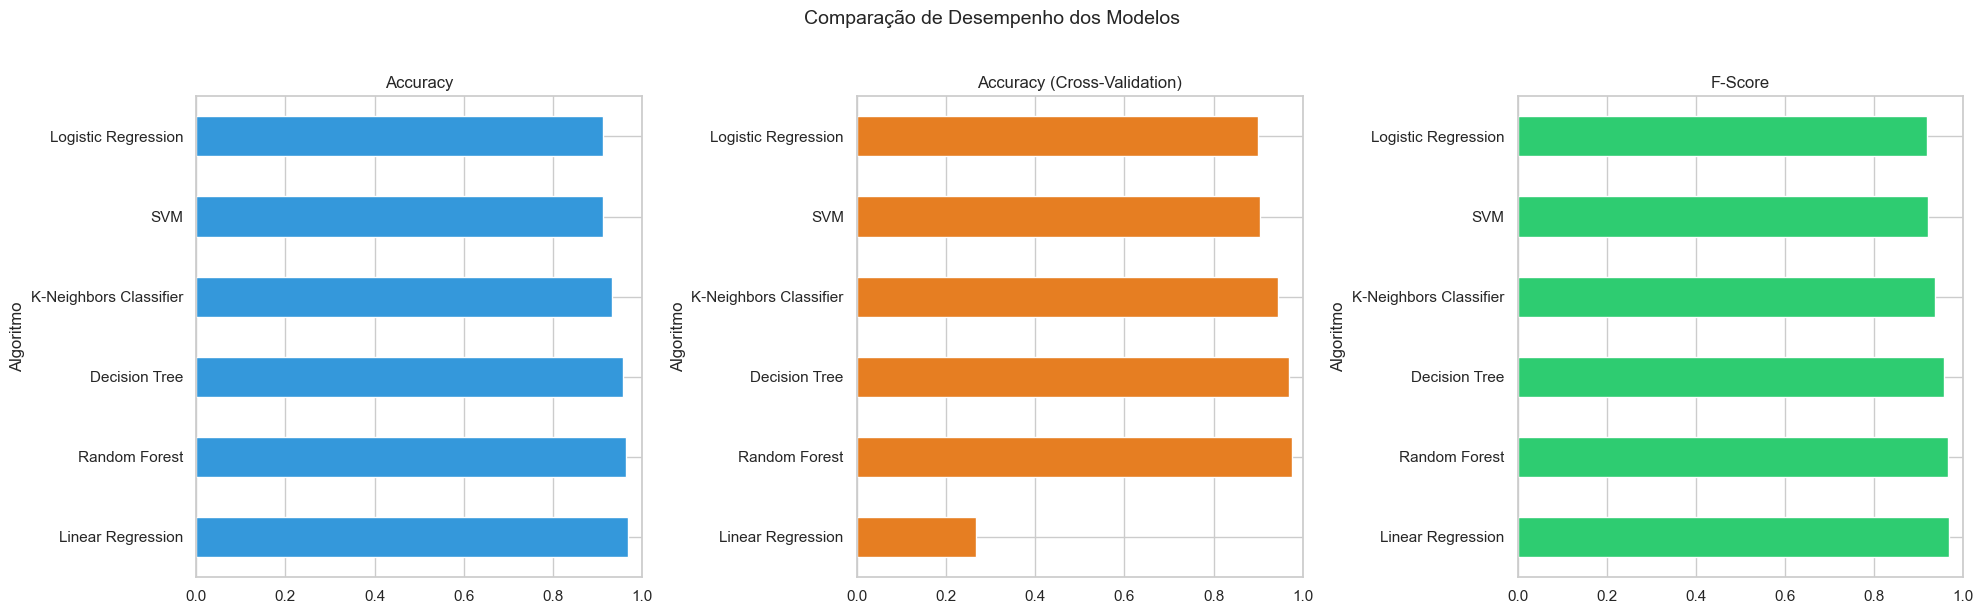

In [19]:
# ============================================================
# CÉLULA 19 — TABELA COMPARATIVA DE MÉTRICAS
# ============================================================
# Esta tabela corresponde EXATAMENTE ao que o enunciado pede:
# Algoritmo | Accuracy | Accuracy CV | F-Score | Time (s)
# ============================================================

df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.set_index('Algoritmo')

# Ordenar pelo F-Score (do melhor para o pior)
df_resultados = df_resultados.sort_values('F-Score', ascending=False)

print("=" * 70)
print("     TABELA COMPARATIVA — DESEMPENHO DOS MODELOS DE ML")
print("=" * 70)
print(df_resultados.to_string())
print("=" * 70)

# Destacar o melhor modelo
melhor_modelo = df_resultados['F-Score'].idxmax()
print(f"\n>>> MELHOR MODELO: {melhor_modelo} (F-Score = {df_resultados.loc[melhor_modelo, 'F-Score']:.4f})")

# Gráfico de barras comparativo
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

df_resultados['Accuracy'].plot(kind='barh', ax=axes[0], color='#3498db')
axes[0].set_title('Accuracy')
axes[0].set_xlim(0, 1)

df_resultados['Accuracy CV'].plot(kind='barh', ax=axes[1], color='#e67e22')
axes[1].set_title('Accuracy (Cross-Validation)')
axes[1].set_xlim(0, 1)

df_resultados['F-Score'].plot(kind='barh', ax=axes[2], color='#2ecc71')
axes[2].set_title('F-Score')
axes[2].set_xlim(0, 1)

plt.suptitle('Comparação de Desempenho dos Modelos', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

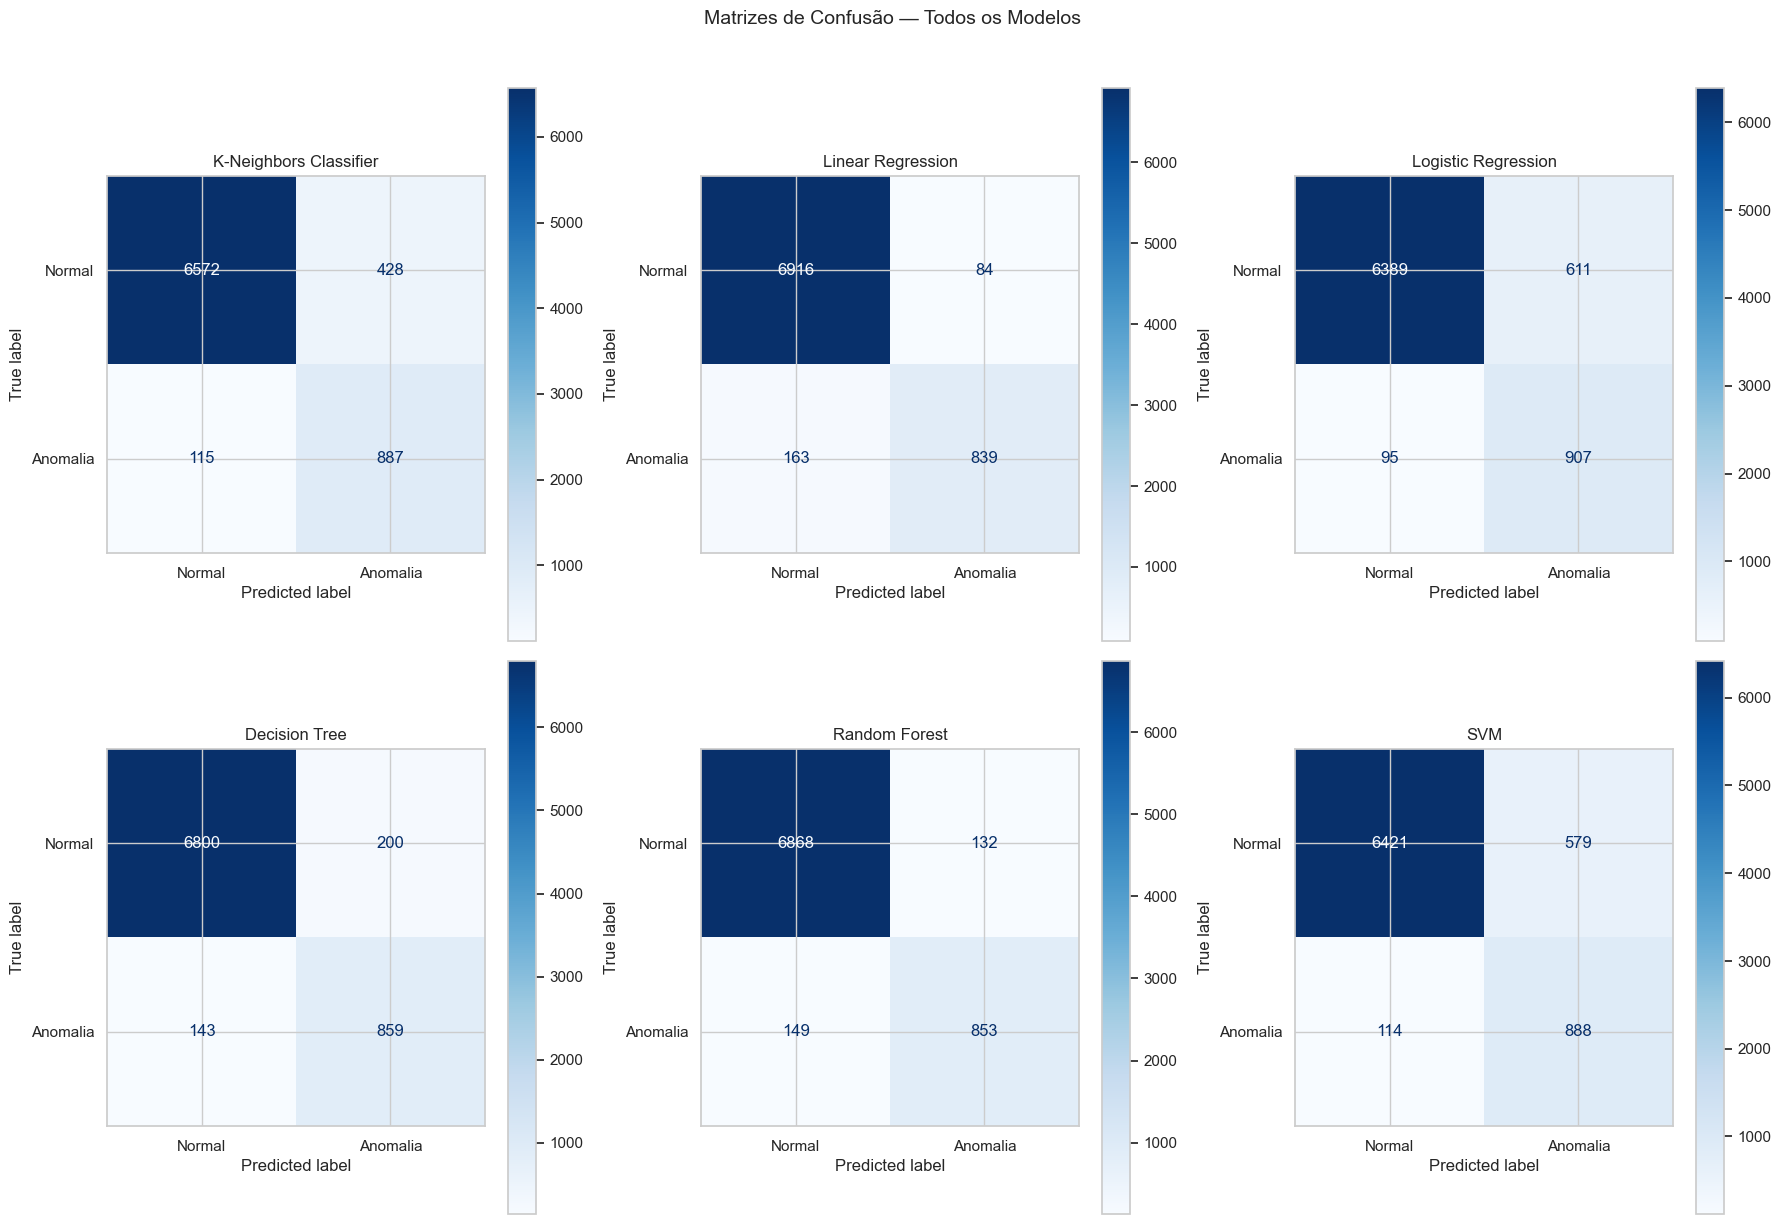

In [20]:
# ============================================================
# CÉLULA 20 — MATRIZES DE CONFUSÃO DE TODOS OS MODELOS
# ============================================================
# A matriz de confusão mostra:
# - Verdadeiros Positivos (TP): Anomalias detetadas corretamente
# - Verdadeiros Negativos (TN): Normais identificados corretamente
# - Falsos Positivos (FP): Normais classificados como anomalias
# - Falsos Negativos (FN): Anomalias não detetadas (o mais perigoso!)
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (nome, modelo) in enumerate(modelos.items()):
    if nome == 'Linear Regression':
        y_pred_cm = (modelo.predict(X_test_scaled) >= 0.5).astype(int)
    else:
        y_pred_cm = modelo.predict(X_test_scaled)
    
    cm = confusion_matrix(y_test, y_pred_cm)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['Normal', 'Anomalia'])
    disp.plot(ax=axes[i], cmap='Blues')
    axes[i].set_title(nome, fontsize=12)

plt.suptitle('Matrizes de Confusão — Todos os Modelos', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 11. Simulação do Uso dos Modelos

O enunciado pede: **"DEPOIS de se criarem os modelos, fazer a simulação do uso dos mesmos para um novo caso de previsão/classificação"**.

Vamos criar 3 cenários fictícios e ver o que cada modelo prevê.

In [21]:
# ============================================================
# CÉLULA 21 — SIMULAÇÃO COM NOVOS CASOS
# ============================================================
# Simulamos 3 cenários de tráfego de rede como se fossem
# dados novos que chegam "em produção" ao sistema de deteção.
#
# Cenário 1: Tráfego normal (valores típicos de uma sessão TLS1.3)
# Cenário 2: Ataque (valores anómalos — alta entropia, proto antigo)
# Cenário 3: Caso ambíguo (valores intermédios, borderline)
#
# Para cada cenário, mostramos o que cada modelo prevê.
# ============================================================

# Usar os valores médios/medianos do dataset como referência
medias = X_all.median()

# --- CENÁRIO 1: TRÁFEGO NORMAL ---
# Uma sessão TLS 1.3 normal com mlkem768, tamanho típico
caso_normal = medias.copy()
# Valores "normais" baseados nas medianas das sessões normais
caso_normal_df = pd.DataFrame([caso_normal.values], columns=feature_names)

# --- CENÁRIO 2: ATAQUE (ANOMALIA) ---
# Simulamos uma sessão com protocolo TLS antigo, alta entropia,
# muitos bytes, e duração curta (exfiltração rápida de dados)
caso_ataque = medias.copy()
# Distorcer os valores para parecer um ataque
for col in caso_ataque.index:
    if 'entropy' in col or 'bytes' in col:
        caso_ataque[col] = caso_ataque[col] + 3 * X_all[col].std()  # Valores extremos
    if 'old_tls' in col:
        caso_ataque[col] = 1  # Protocolo antigo (inseguro)
    if 'duration' in col or 'time' in col:
        caso_ataque[col] = caso_ataque[col] - 2 * X_all[col].std()  # Sessão curta
caso_ataque_df = pd.DataFrame([caso_ataque.values], columns=feature_names)

# --- CENÁRIO 3: CASO AMBÍGUO ---
# Valores entre o normal e o anómalo
caso_ambiguo = medias.copy()
for col in caso_ambiguo.index:
    if 'entropy' in col:
        caso_ambiguo[col] = caso_ambiguo[col] + 1 * X_all[col].std()  # Ligeiramente alto
caso_ambiguo_df = pd.DataFrame([caso_ambiguo.values], columns=feature_names)

# Filtrar apenas as features selecionadas
cenarios = {
    'Trafego Normal': caso_normal_df[features_selecionadas],
    'Ataque (Anomalia)': caso_ataque_df[features_selecionadas],
    'Caso Ambiguo': caso_ambiguo_df[features_selecionadas],
}

# Fazer previsões com cada modelo para cada cenário
print("=" * 70)
print("     SIMULAÇÃO — PREVISÃO PARA NOVOS CASOS")
print("=" * 70)

for nome_cenario, dados_cenario in cenarios.items():
    print(f"\n--- {nome_cenario.upper()} ---")
    # Escalar com o mesmo scaler usado no treino
    dados_scaled = scaler_final.transform(dados_cenario)
    
    for nome_modelo, modelo in modelos.items():
        if nome_modelo == 'Linear Regression':
            pred_raw = modelo.predict(dados_scaled)[0]
            pred = 1 if pred_raw >= 0.5 else 0
            label = 'ANOMALIA' if pred == 1 else 'NORMAL'
            print(f"  {nome_modelo:<25} -> {label} (valor bruto: {pred_raw:.4f})")
        else:
            pred = modelo.predict(dados_scaled)[0]
            label = 'ANOMALIA' if pred == 1 else 'NORMAL'
            print(f"  {nome_modelo:<25} -> {label}")

print(f"\n{'='*70}")
print("Simulacao concluida. Os modelos estao prontos para uso em producao.")

     SIMULAÇÃO — PREVISÃO PARA NOVOS CASOS

--- TRAFEGO NORMAL ---
  K-Neighbors Classifier    -> ANOMALIA
  Linear Regression         -> ANOMALIA (valor bruto: 0.7801)
  Logistic Regression       -> NORMAL
  Decision Tree             -> NORMAL
  Random Forest             -> NORMAL
  SVM                       -> ANOMALIA

--- ATAQUE (ANOMALIA) ---
  K-Neighbors Classifier    -> NORMAL
  Linear Regression         -> NORMAL (valor bruto: -0.8970)
  Logistic Regression       -> NORMAL
  Decision Tree             -> NORMAL
  Random Forest             -> NORMAL
  SVM                       -> NORMAL

--- CASO AMBIGUO ---
  K-Neighbors Classifier    -> ANOMALIA
  Linear Regression         -> ANOMALIA (valor bruto: 0.8319)
  Logistic Regression       -> NORMAL
  Decision Tree             -> NORMAL
  Random Forest             -> NORMAL
  SVM                       -> NORMAL

Simulacao concluida. Os modelos estao prontos para uso em producao.


In [22]:
# ============================================================
# CÉLULA 22 — GUARDAR MODELOS E RESULTADOS
# ============================================================
# Guardamos os modelos treinados e a tabela de resultados
# para uso futuro (simulação, apresentação, etc.)
# ============================================================
import joblib
import os

# Criar pasta para os modelos
os.makedirs('../models', exist_ok=True)

# Guardar cada modelo treinado
for nome, modelo in modelos.items():
    nome_ficheiro = nome.lower().replace(' ', '_').replace('-', '_')
    caminho = f'../models/{nome_ficheiro}.pkl'
    joblib.dump(modelo, caminho)
    print(f"Modelo '{nome}' guardado em: {caminho}")

# Guardar também o scaler (necessário para novos dados)
joblib.dump(scaler_final, '../models/scaler.pkl')
print("Scaler guardado em: ../models/scaler.pkl")

# Guardar a lista de features selecionadas
joblib.dump(features_selecionadas, '../models/features_selecionadas.pkl')
print("Features selecionadas guardadas em: ../models/features_selecionadas.pkl")

# Guardar o PowerTransformer (para normalizar novos dados)
joblib.dump(pt, '../models/power_transformer.pkl')
print("PowerTransformer guardado em: ../models/power_transformer.pkl")

# Guardar tabela de resultados como CSV
df_resultados.to_csv('../data/resultados_modelos.csv')
print("\nTabela de resultados guardada em: ../data/resultados_modelos.csv")
print("\nPipeline completo. Tudo guardado.")

Modelo 'K-Neighbors Classifier' guardado em: ../models/k_neighbors_classifier.pkl
Modelo 'Linear Regression' guardado em: ../models/linear_regression.pkl
Modelo 'Logistic Regression' guardado em: ../models/logistic_regression.pkl
Modelo 'Decision Tree' guardado em: ../models/decision_tree.pkl
Modelo 'Random Forest' guardado em: ../models/random_forest.pkl
Modelo 'SVM' guardado em: ../models/svm.pkl
Scaler guardado em: ../models/scaler.pkl
Features selecionadas guardadas em: ../models/features_selecionadas.pkl
PowerTransformer guardado em: ../models/power_transformer.pkl

Tabela de resultados guardada em: ../data/resultados_modelos.csv

Pipeline completo. Tudo guardado.
